In [1]:
import pygad
import axelrod as axl
from axelrod.action import Action, actions_to_str
from axelrod.player import Player
from axelrod.strategy_transformers import (
    FinalTransformer,
    TrackHistoryTransformer,
)
import skfuzzy as fuzz
from skfuzzy import control as ctrl
import numpy as np
from collections import Counter
import pandas as pd
from math import exp
import numpy as np


In [ ]:
C, D = Action.C, Action.D

class FuzzyMethods():
    @staticmethod
    def sigmoid(x, center, scale=10):
        return 1 / (1 + exp(-scale * (x - center)))
    
    @staticmethod
    def fuzzy_gate(mu_D, d_thresh, mu_C, c_thresh):
            d_condition = FuzzyMethods.sigmoid(mu_D, center=d_thresh)
            c_condition = 1 - FuzzyMethods.sigmoid(mu_C, center=c_thresh)
    
            w1 = d_condition * c_condition
            
            return w1
    
    @staticmethod
    def calc_cooperation(self, opponent):
        return (Counter(opponent.history)[C])/len(opponent.history)*100
    
    @staticmethod
    def calc_adaptivity(self, opponent):
        adapCounter = 0
        adapReaction = 0

        if(len(self.history) < 3): 
            return 0
        
        for i in range(3, len(self.history)):
            if (self.history[i-3] == C and self.history[i-2] == D):
                adapCounter += 1
                if (opponent.history[i-1] == D):
                    adapReaction += 1
                elif (self.history[i-1] == D and opponent.history[i] == D):
                    adapReaction += 0.5
            elif (self.history[i-3] == D and self.history[i-2] == C):
                adapCounter += 1
                if (opponent.history[i-1] == C):
                    adapReaction += 1
                elif (self.history[i-1] == C and opponent.history[i] == C):
                    adapReaction += 0.5

        if adapCounter == 0:
            return 0
        
        return adapReaction/adapCounter*100

    
    @staticmethod
    def calc_forgiveness(self, opponent):
        DCounter = 0
        punishmentCounter = 0

        for i in range(0, len(self.history)-1):
            if(self.history[i] == D):
                DCounter += 1
                for j in range (i+1, len(opponent.history)):
                    if(opponent.history[j] == C):
                        break
                    else:
                        punishmentCounter += 1
              

        if punishmentCounter > 0:
            return DCounter/punishmentCounter*100
        else:
            return 100
    
    @staticmethod
    def calc_stochastic(self, opponent):
        patterns = [
            [C, C, C],
            [C, C, D],
            [C, D, C],
            [C, D, D],
            [D, C, C],
            [D, C, D],
            [D, D, C],
            [D, D, D]
        ]

        non_stochasticCounter = 0
        patternPlayedCounter = 0

        for p in patterns:
            opponentsReactions = []
            for i in range(0, len(self.history)-3):
                if ([self.history[i], self.history[i+1], self.history[i+2]] == p):
                    opponentsReactions.append([opponent.history[i+1], opponent.history[i+2], opponent.history[i+3]])
            
            unique_patterns = len(set(tuple(sub) for sub in opponentsReactions))

            if(len(opponentsReactions) > 0):
                non_stochasticCounter += 0 if unique_patterns == 1 else unique_patterns
                patternPlayedCounter += len(opponentsReactions)
        
        if patternPlayedCounter == 0:
            return 0
        
        return non_stochasticCounter/patternPlayedCounter*100

In [3]:
def build_player(params): 
    class FSOptimized(Player):

        name = "FuzzySugeno"
        classifier = {
            "memory_depth": float("inf"),
            "stochastic": False,
            "long_run_time": False,
            "inspects_source": False,
            "manipulates_source": False,
            "manipulates_state": False,
        }

        cooperation = ctrl.Antecedent(np.arange(0, 100, 1), 'cooperation')
        adaptivity = ctrl.Antecedent(np.arange(0, 100, 1), 'adaptivity')
        forgiveness = ctrl.Antecedent(np.arange(0, 100, 1), 'forgiveness')
        stochastic = ctrl.Antecedent(np.arange(0, 100, 1), 'stochastic')

        cooperation.automf(names=["low", "medium", "high"])
        adaptivity.automf(names=["no", "yes"])
        forgiveness.automf(names=["low", "medium", "high"])
        forgiveness['low'] = fuzz.gaussmf(forgiveness.universe, 0, 25)
        forgiveness['medium'] = fuzz.trimf(forgiveness.universe, [25, 50, 75])
        stochastic.automf(names=["none", "sometimes", "always"])

        resulting_strategy = ctrl.Consequent(np.arange(0, 100, 1),'resulting_strategy')
        resulting_strategy['D'] = fuzz.trimf(resulting_strategy.universe, [0, 25, 50])
        resulting_strategy['C'] = fuzz.trimf(resulting_strategy.universe, [35, 75, 100])

        rule1 = ctrl.Rule(cooperation['high'] & adaptivity['no'] & (forgiveness['medium'] | forgiveness['high']), resulting_strategy['D'])
        rule2 = ctrl.Rule(forgiveness['low'] & cooperation['high'], resulting_strategy['C'])
        rule3 = ctrl.Rule(stochastic['always'] | adaptivity['no'], resulting_strategy['D'])
        rule4 = ctrl.Rule(cooperation['low'] | (cooperation['medium'] & forgiveness['low']), resulting_strategy['D'])
        rule5 = ctrl.Rule(cooperation['medium'] & forgiveness['medium'] & adaptivity['yes'], resulting_strategy['C'])

        strategy_ctrl = ctrl.ControlSystem([rule1, rule2, rule3, rule4, rule5])
        chosen_strategy = ctrl.ControlSystemSimulation(strategy_ctrl)

        h = {'Name':'', 'Fuzzy' : [], 'Opponent': []}

        forgiveness_index = 0
        stochastic_index = 0
        first_time = True
    
        def strategy(self, opponent: Player) -> Action:

            if(len(self.history) == 0 or D not in opponent.history):
                return C
            
            else:
                coop = FuzzyMethods.calc_cooperation(self, opponent)
                adap = FuzzyMethods.calc_adaptivity(self, opponent)
                forg = FuzzyMethods.calc_forgiveness(self, opponent)
                stoch = FuzzyMethods.calc_stochastic(self, opponent)

                self.chosen_strategy.input['cooperation'] = coop
                self.chosen_strategy.input['adaptivity'] = adap
                self.chosen_strategy.input['forgiveness'] = forg
                self.chosen_strategy.input['stochastic'] = stoch
                
                self.chosen_strategy.compute()

                d_membership = fuzz.interp_membership(self.resulting_strategy.universe, self.resulting_strategy['D'].mf, self.chosen_strategy.output['resulting_strategy'])
                c_membership = fuzz.interp_membership(self.resulting_strategy.universe, self.resulting_strategy['C'].mf, self.chosen_strategy.output['resulting_strategy'])

                output = FuzzyMethods.fuzzy_gate(d_membership, params[0], c_membership, params[1])

                if(output > 0.5):
                    return D
            
            return C
    return FSOptimized()

In [4]:
i = 0
def fitness_function(ga_instance, solution, solution_idx):
    global i
    print(f"Evaluating solution {i} {solution_idx}: {solution}")
    if solution_idx == 7:
        i+=1
    results = axl.Tournament(players=[build_player(solution)] + [player() for player in axl.stewart_plotkin_strategies], turns=200).play(progress_bar=False)
    return np.mean(results.normalised_scores[0])


In [5]:
num_generations = 50
num_parents_mating = 4

# sol_per_pop = 8
# num_genes = 2

init_range_low = 0
init_range_high = 1

parent_selection_type = "sss"
keep_parents = 1

crossover_type = "single_point"

mutation_type = "random"
mutation_percent_genes = 10

initial_population = [[0.4, 0.6], [0.45, 0.55], [0.5, 0.5], [0.2, 0.8], [0, 1], [0.1, 0.9], [0.3, 0.7], [0.2, 0.8]]

In [6]:
ga_instance = pygad.GA(num_generations=num_generations,
                       num_parents_mating=num_parents_mating,
                       fitness_func=fitness_function,
                       initial_population=initial_population,
                    #    sol_per_pop=sol_per_pop,
                    #    num_genes=num_genes,
                       init_range_low=init_range_low,
                       init_range_high=init_range_high,
                       gene_space={'low': 0, 'high': 1},
                       gene_constraint = [
                            lambda solution, values: [v for v in values if v <= solution[1]],  
                            lambda solution, values: [v for v in values if v >= solution[0]],  
                        ],
                       parent_selection_type=parent_selection_type,
                       keep_parents=keep_parents,
                       crossover_type=crossover_type,
                       mutation_type=mutation_type,
                       mutation_percent_genes=mutation_percent_genes)

c:\Users\Ognjen\AppData\Local\Programs\Python\Python311\Lib\site-packages\pygad\utils\validation.py:690: UserWarning: The percentage of genes to mutate (mutation_percent_genes=10) resulted in selecting (0) genes. The number of genes to mutate is set to 1 (mutation_num_genes=1).
If you do not want to mutate any gene, please set mutation_type=None.
  warnings.warn(f"The percentage of genes to mutate (mutation_percent_genes={mutation_percent_genes}) resulted in selecting ({mutation_num_genes}) genes. The number of genes to mutate is set to 1 (mutation_num_genes=1).\nIf you do not want to mutate any gene, please set mutation_type=None.")


In [7]:
ga_instance.run()

Evaluating solution 0 0: [0.4 0.6]
Evaluating solution 0 1: [0.45 0.55]
Evaluating solution 0 2: [0.5 0.5]
Evaluating solution 0 3: [0.2 0.8]
Evaluating solution 0 4: [0. 1.]
Evaluating solution 0 5: [0.1 0.9]
Evaluating solution 0 6: [0.3 0.7]
Evaluating solution 0 7: [0.2 0.8]
Evaluating solution 1 1: [0.45506478 0.5       ]
Evaluating solution 1 2: [0.1591178 0.55     ]
Evaluating solution 1 3: [0.2        0.47435938]
Evaluating solution 1 4: [0.29144406 0.6       ]
Evaluating solution 1 5: [0.4        0.57159282]
Evaluating solution 1 6: [0.5        0.81625657]
Evaluating solution 1 7: [0.2        0.45402426]
Evaluating solution 2 1: [0.4        0.86378326]
Evaluating solution 2 2: [0.4388307  0.57159282]
Evaluating solution 2 3: [0.4        0.95209667]
Evaluating solution 2 4: [0.5        0.97230424]
Evaluating solution 2 5: [0.5        0.92808985]
Evaluating solution 2 6: [0.2386734  0.57159282]
Evaluating solution 2 7: [0.45506478 0.68380899]
Evaluating solution 3 1: [0.45506478

Evaluating solution 51 2: [0.32348161 0.97375389]
Evaluating solution 51 4: [0.87442932 0.93913994]
Evaluating solution 51 6: [0.44755304 0.97375389]
Evaluating solution 51 7: [0.91984766 0.98164158]


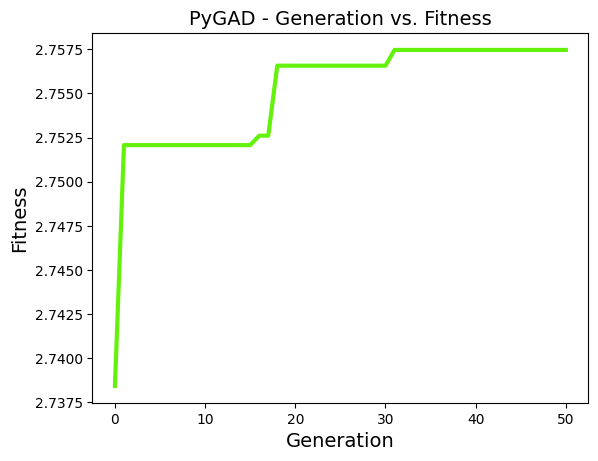

The plot_genes() method with solutions='all' can only be called if 'save_solutions=True' in the pygad.GA class constructor.


RuntimeError: The plot_genes() method with solutions='all' can only be called if 'save_solutions=True' in the pygad.GA class constructor.

In [ ]:
solution, solution_fitness, solution_idx = ga_instance.best_solution()
ga_instance.plot_fitness()

In [9]:
ga_instance.save("ga_results")
print("Parameters of the best solution : {solution}".format(solution=solution))
print("Fitness value of the best solution = {solution_fitness}".format(solution_fitness=solution_fitness))

Parameters of the best solution : [0.91984766 0.98164158]
Fitness value of the best solution = 2.7576071428571427
